# Step 1: Dataset Preparation (CIFAR-10) - Warning: The size is 170MB so DL takes time

For this implementation, we will use the **CIFAR-10** dataset. Since ViT models typically expect larger images (e.g., $224 \times 224$), we will include a resizing transformation step to make the transitions smoother later on.

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Define image resolution (ViT standard is often 224x224, but we can use 224 or a smaller custom size)
IMG_SIZE = 224
BATCH_SIZE = 128

# Define training and validation/test transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Download and load CIFAR-10
train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=test_transform
)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Quick sanity check
images, labels = next(iter(train_loader))
print(f"Training batch image shape: {images.shape}")  # Expected: [batch_size, 3, 224, 224]
print(f"Training batch label shape: {labels.shape}")

100%|██████████| 170M/170M [21:18<00:00, 133kB/s]


Training batch image shape: torch.Size([128, 3, 224, 224])
Training batch label shape: torch.Size([128])


### Step 2: Visualizing the Dataset (6x6 Grid)
To confirm our dataset is loaded correctly, we will display a 6x6 grid of images. Note that we must first **unnormalize** the images back to $[0, 1]$ so that they render with correct colors.

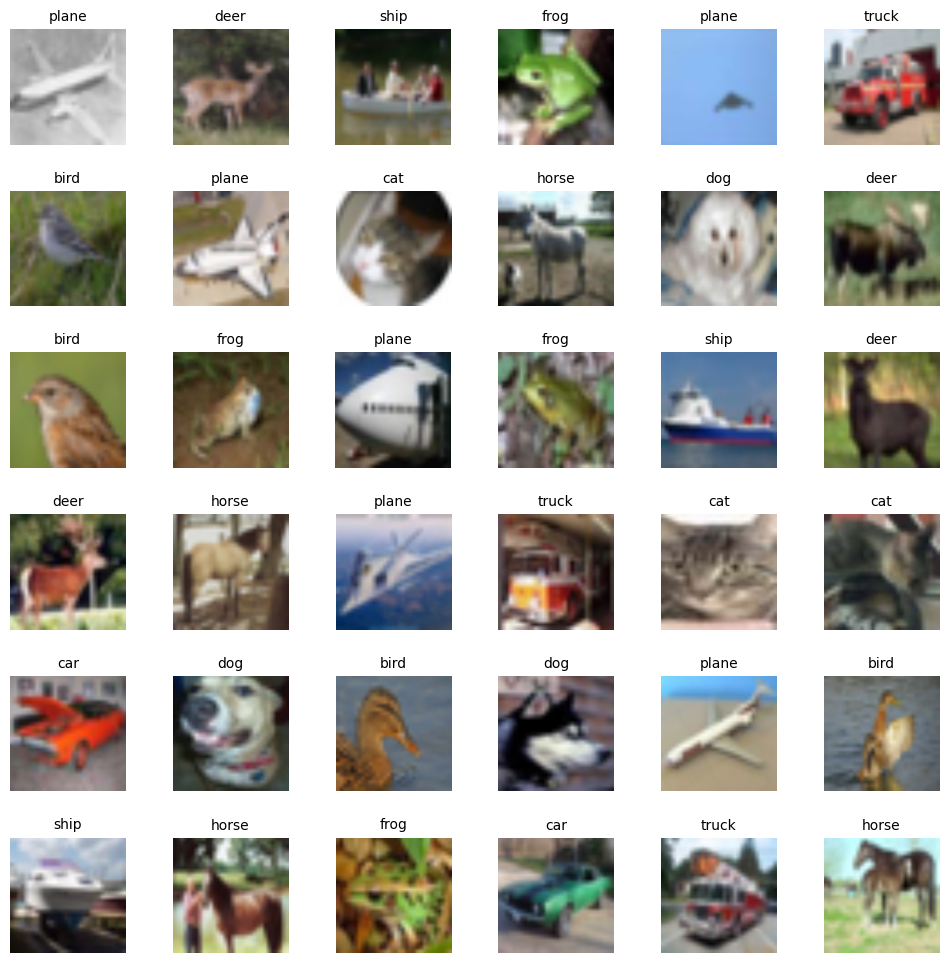

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Helper function to unnormalize and convert tensor to numpy for plotting
def imshow(img):
    # Reverse normalization: img = std * normalized_img + mean
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img = img.numpy().transpose((1, 2, 0)) # Convert from CHW to HWC
    img = std * img + mean                 # Unnormalize
    img = np.clip(img, 0, 1)               # Clip values to [0, 1] range
    return img

# Get a batch of training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

# CIFAR-10 Class Names
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# Create a 6x6 grid plot
fig, axes = plt.subplots(6, 6, figsize=(12, 12))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

for i in range(36):
    row = i // 6
    col = i % 6
    ax = axes[row, col]

    # Unnormalize and display
    np_img = imshow(images[i])
    ax.imshow(np_img)

    # Set title with the class name
    ax.set_title(classes[labels[i]], fontsize=10)
    ax.axis('off')

plt.show()

### Step 3: Patch Extraction & Linear Projection

Here, we implement the `PatchEmbedding` layer.
* For an image of size $224 \times 224$ and patch size $P=16$, the number of patches $N$ is $(224 \times 224) / (16 \times 16) = 196$.
* We reshape the input tensor from `(B, C, H, W)` to `(B, N, P * P * C)`.
* We then project it using a Linear layer to size `(B, N, d)`, where $d = 128$.

In [3]:
import torch.nn as nn

class PatchEmbedding(nn.Module):
    def __init__(self, in_channels=3, patch_size=16, embed_dim=128):
        super().__init__()
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        # Number of features per flattened patch (P * P * C)
        self.patch_dim = in_channels * patch_size * patch_size

        # Linear projection layer
        self.projection = nn.Linear(self.patch_dim, embed_dim)

    def forward(self, x):
        # x shape: (B, C, H, W)
        B, C, H, W = x.shape
        P = self.patch_size

        # Ensure image dimensions are divisible by the patch size
        assert H % P == 0 and W % P == 0, "Image dimensions must be divisible by the patch size."

        num_patches_h = H // P
        num_patches_w = W // P
        num_patches = num_patches_h * num_patches_w

        # 1. Reshape into patches: (B, C, num_patches_h, P, num_patches_w, P)
        # 2. Permute to get patches grouped: (B, num_patches_h, num_patches_w, P, P, C)
        # 3. Flatten into (B, N, P * P * C)
        x = x.view(B, C, num_patches_h, P, num_patches_w, P)
        x = x.permute(0, 2, 4, 3, 5, 1).contiguous()
        x = x.view(B, num_patches, self.patch_dim)

        # Apply linear projection -> (B, N, d)
        out = self.projection(x)
        return out

# Verification with a single batch
patch_embedder = PatchEmbedding(in_channels=3, patch_size=16, embed_dim=128)
embedded_patches = patch_embedder(images)

print(f"Input image batch shape: {images.shape}")
print(f"Output patch embedding shape (B, N, d): {embedded_patches.shape}" )

Input image batch shape: torch.Size([128, 3, 224, 224])
Output patch embedding shape (B, N, d): torch.Size([128, 196, 128])


### Step 4: CLS Token and Position Embeddings

Here we implement a wrapper/extension or a helper logic to prepended the learnable `class_token` and add the 1D learnable `position_embeddings` to the sequence.
* If we have $N=196$ patches, our sequence length becomes $N + 1 = 197$ after prepending the class token.
* The position embeddings will therefore have a shape of `(1, N + 1, d)` so they can be broadcast and added across the batch.

In [4]:
import torch
import torch.nn as nn

class ViTInputEmbeddings(nn.Module):
    def __init__(self, in_channels=3, patch_size=16, embed_dim=128, img_size=224):
        super().__init__()
        self.patch_embeddings = PatchEmbedding(in_channels, patch_size, embed_dim)

        # Number of patches N
        num_patches = (img_size // patch_size) ** 2

        # Learnable CLS Token: shape (1, 1, d)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

        # Learnable Position Embeddings: shape (1, N + 1, d)
        self.pos_embeddings = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))

        # Initialize parameters with small random values
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embeddings, std=0.02)

    def forward(self, x):
        # 1. Extract and project patches -> (B, N, d)
        x = self.patch_embeddings(x)
        B, N, d = x.shape

        # 2. Expand CLS token to match batch size: (B, 1, d)
        cls_tokens = self.cls_token.expand(B, -1, -1)

        # 3. Concatenate CLS token with patch embeddings -> (B, N + 1, d)
        x = torch.cat((cls_tokens, x), dim=1)

        # 4. Add Position Embeddings -> (B, N + 1, d)
        x = x + self.pos_embeddings

        return x

# Verification with a single batch
vit_embeddings = ViTInputEmbeddings(in_channels=3, patch_size=16, embed_dim=128, img_size=224)
final_embeddings = vit_embeddings(images)

print(f"Patch embedding output shape: {embedded_patches.shape}")
print(f"Final sequence embedding shape (including CLS token & Positional IDs): {final_embeddings.shape}")

Patch embedding output shape: torch.Size([128, 196, 128])
Final sequence embedding shape (including CLS token & Positional IDs): torch.Size([128, 197, 128])


### Step 5: Layer Normalization

We will implement a custom `LayerNorm` module from scratch. It calculates the mean and variance across the last dimension (the embedding dimension $d$) and applies learnable scale (gamma) and shift (beta) parameters.

In [5]:
import torch
import torch.nn as nn

class CustomLayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-6):
        super().__init__()
        self.eps = eps
        # Learnable parameters: gamma (weight) and beta (bias)
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))

    def forward(self, x):
        # x shape: (B, N + 1, d_model)
        # Calculate mean across the embedding dimension (dim=-1)
        mean = x.mean(dim=-1, keepdim=True)

        # Calculate variance across the embedding dimension (dim=-1)
        var = x.var(dim=-1, keepdim=True, unbiased=False)

        # Normalize and apply scale (gamma) and shift (beta)
        x_norm = (x - mean) / torch.sqrt(var + self.eps)
        out = self.gamma * x_norm + self.beta

        return out

# Verification with our embeddings
custom_ln = CustomLayerNorm(d_model=128)
normalized_embeddings = custom_ln(final_embeddings)

print(f"Sequence embeddings shape: {final_embeddings.shape}")
print(f"Normalized embeddings shape: {normalized_embeddings.shape}")

# Sanity check: Mean should be ~0 and Variance should be ~1 across the feature dimension for any token
print(f"Mean of first token (first batch item) after normalization: {normalized_embeddings[0, 0].mean().item():.6f}")
print(f"Variance of first token (first batch item) after normalization: {normalized_embeddings[0, 0].var(unbiased=False).item():.6f}")

Sequence embeddings shape: torch.Size([128, 197, 128])
Normalized embeddings shape: torch.Size([128, 197, 128])
Mean of first token (first batch item) after normalization: -0.000000
Variance of first token (first batch item) after normalization: 0.998732


### Step 6: Single-Head Self-Attention

First, we implement a single attention head. Given input $X \in \mathbb{R}^{B \times L \times d}$:
1. Project to $Q, K, V$:
   $$Q = X W_Q, \quad K = X W_K, \quad V = X W_V$$
2. Compute scaled dot-product attention:
   $$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$
   where $d_k$ is the dimension of the keys (here $d_k = d = 128$).

In [6]:
import math
import torch
import torch.nn as nn

class SingleHeadSelfAttention(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model

        # Linear projections for Query, Key, and Value
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)

        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        # x shape: (B, L, d_model)
        B, L, d = x.shape

        # 1. Project inputs
        Q = self.w_q(x)  # (B, L, d)
        K = self.w_k(x)  # (B, L, d)
        V = self.w_v(x)  # (B, L, d)

        # 2. Scaled dot-product: Q @ K.T
        # We transpose the last two dimensions of K to do batch matrix multiplication
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d)  # (B, L, L)

        # 3. Softmax to get attention weights
        attention_weights = self.softmax(scores)  # (B, L, L)

        # 4. Multiply weights by V
        out = torch.matmul(attention_weights, V)  # (B, L, d)

        return out, attention_weights

# Quick validation
single_head_attn = SingleHeadSelfAttention(d_model=128)
attn_out, attn_weights = single_head_attn(normalized_embeddings)

print(f"Single-Head Output Shape: {attn_out.shape}")
print(f"Attention Map Shape: {attn_weights.shape}")

Single-Head Output Shape: torch.Size([128, 197, 128])
Attention Map Shape: torch.Size([128, 197, 197])


### Step 7: Multi-Head Self-Attention (MHSA)

Now, we scale this to $h$ heads. Instead of doing attention once over dimension $d$, we split the embedding space into $h$ subspaces of dimension $d_k = d / h$. We run attention on these subspaces in parallel and concatenate the outputs at the end.

In [7]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads=8):
        super().__init__()
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        assert self.head_dim * num_heads == d_model, "d_model must be divisible by num_heads"

        # We can project all heads at once using a single Linear layer for Q, K, and V
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)

        # Final output projection
        self.w_o = nn.Linear(d_model, d_model)

        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        B, L, d = x.shape
        h = self.num_heads
        d_k = self.head_dim

        # 1. Linear projection -> (B, L, d)
        Q = self.w_q(x)
        K = self.w_k(x)
        V = self.w_v(x)

        # 2. Reshape to split the dimension d into h heads: (B, L, h, d_k)
        # and transpose to (B, h, L, d_k) for batch matrix multiplication per head
        Q = Q.view(B, L, h, d_k).transpose(1, 2)
        K = K.view(B, L, h, d_k).transpose(1, 2)
        V = V.view(B, L, h, d_k).transpose(1, 2)

        # 3. Scaled dot-product attention per head
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)  # (B, h, L, L)
        attention_weights = self.softmax(scores)                         # (B, h, L, L)

        # 4. Apply attention to values: (B, h, L, d_k)
        out = torch.matmul(attention_weights, V)

        # 5. Concatenate heads back together -> (B, L, d)
        out = out.transpose(1, 2).contiguous().view(B, L, d)

        # 6. Final linear projection
        out = self.w_o(out)

        return out, attention_weights

# Validation
mhsa = MultiHeadSelfAttention(d_model=128, num_heads=8)
mhsa_out, mhsa_weights = mhsa(normalized_embeddings)

print(f"MHSA Output Shape: {mhsa_out.shape}")
print(f"MHSA Attention Weights Shape (B, h, L, L): {mhsa_weights.shape}")

MHSA Output Shape: torch.Size([128, 197, 128])
MHSA Attention Weights Shape (B, h, L, L): torch.Size([128, 8, 197, 197])


### Step 8: Multi-Layer Perceptron (MLP) Block

In a Transformer Encoder, the Multi-Head Attention layer is followed by a feed-forward network (MLP). This MLP consists of two linear layers with a GELU non-linearity in between, and typically a dropout layer for regularization.

The first linear layer projects the dimension from $d$ to a larger hidden dimension $d_{mlp}$ (usually $4 \times d$), and the second projects it back to $d$.

In [8]:
class MLP(nn.Module):
    def __init__(self, d_model, d_mlp, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_mlp)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_mlp, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x

# Validation
mlp_block = MLP(d_model=128, d_mlp=512)
mlp_out = mlp_block(normalized_embeddings)
print(f"MLP Output Shape: {mlp_out.shape}")

MLP Output Shape: torch.Size([128, 197, 128])


### Step 9: Assembling the Complete Transformer Encoder Block

Now we combine our customized modules (`CustomLayerNorm`, `MultiHeadSelfAttention`, and `MLP`) into a single **TransformerEncoderBlock** with Pre-Layer Normalization (Pre-LN) and residual connections.

In [9]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_mlp, dropout=0.1):
        super().__init__()
        self.ln1 = CustomLayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, num_heads)
        self.ln2 = CustomLayerNorm(d_model)
        self.mlp = MLP(d_model, d_mlp, dropout)

    def forward(self, x):
        # First Sublayer: LN -> MHSA -> Residual Connection
        attn_out, weights = self.attn(self.ln1(x))
        x = x + attn_out

        # Second Sublayer: LN -> MLP -> Residual Connection
        mlp_out = self.mlp(self.ln2(x))
        x = x + mlp_out

        return x, weights

# Validation
encoder_block = TransformerEncoderBlock(d_model=128, num_heads=8, d_mlp=512)
block_out, attn_weights = encoder_block(final_embeddings)

print(f"Transformer Block Input Shape: {final_embeddings.shape}")
print(f"Transformer Block Output Shape: {block_out.shape}")

Transformer Block Input Shape: torch.Size([128, 197, 128])
Transformer Block Output Shape: torch.Size([128, 197, 128])


### Step 10: The Full Vision Transformer (ViT) Model

We stack multiple `TransformerEncoderBlock` layers sequentially. After passing the input sequence through the encoder blocks, we extract the first token's output representation (which corresponds to the class token, `CLS`) and pass it through a classification head (a LayerNorm followed by a Linear layer) to predict the logits.

In [10]:
class VisionTransformer(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3, num_classes=10,
                 d_model=128, depth=4, num_heads=8, d_mlp=512, dropout=0.1):
        super().__init__()

        # 1. Patch & Position Embeddings
        self.embeddings = ViTInputEmbeddings(in_channels, patch_size, d_model, img_size)
        self.dropout = nn.Dropout(dropout)

        # 2. Stack of Transformer Encoder Blocks
        self.encoders = nn.ModuleList([
            TransformerEncoderBlock(d_model, num_heads, d_mlp, dropout)
            for _ in range(depth)
        ])

        # 3. Pre-head Layer Normalization (standard in ViT pre-training)
        self.ln = CustomLayerNorm(d_model)

        # 4. Classification Head
        self.head = nn.Linear(d_model, num_classes)

    def forward(self, x):
        # x shape: (B, C, H, W)
        x = self.embeddings(x)  # (B, N+1, d_model)
        x = self.dropout(x)

        # Pass through each transformer block
        for encoder in self.encoders:
            x, _ = encoder(x)

        # Extract the representation of the CLS token (index 0)
        cls_repr = x[:, 0]  # (B, d_model)

        # Normalize and project to classes
        cls_repr = self.ln(cls_repr)
        logits = self.head(cls_repr)  # (B, num_classes)

        return logits

# Verification
vit_model = VisionTransformer(img_size=224, patch_size=16, in_channels=3, num_classes=10,
                              d_model=128, depth=4, num_heads=8, d_mlp=512)
print(vit_model)

VisionTransformer(
  (embeddings): ViTInputEmbeddings(
    (patch_embeddings): PatchEmbedding(
      (projection): Linear(in_features=768, out_features=128, bias=True)
    )
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (encoders): ModuleList(
    (0-3): 4 x TransformerEncoderBlock(
      (ln1): CustomLayerNorm()
      (attn): MultiHeadSelfAttention(
        (w_q): Linear(in_features=128, out_features=128, bias=True)
        (w_k): Linear(in_features=128, out_features=128, bias=True)
        (w_v): Linear(in_features=128, out_features=128, bias=True)
        (w_o): Linear(in_features=128, out_features=128, bias=True)
        (softmax): Softmax(dim=-1)
      )
      (ln2): CustomLayerNorm()
      (mlp): MLP(
        (fc1): Linear(in_features=128, out_features=512, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=512, out_features=128, bias=True)
        (drop): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln): CustomLayerNorm()
  (head): Line

### Step 11: Setup & Pre-training Loop

We set up the optimizer (AdamW, as utilized in the paper), the loss function (CrossEntropyLoss), and the training/validation loop. We will also run a brief training pass to verify the loop executes correctly.

In [15]:
import torch.optim as optim
from tqdm.notebook import tqdm

# Device setup (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Instantiate our Custom ViT Model
model = VisionTransformer(
    img_size=224,
    patch_size=16,
    in_channels=3,
    num_classes=10,
    d_model=128,  # Kept smaller for rapid Colab training
    depth=4,
    num_heads=8,
    d_mlp=512,
    dropout=0.1
).to(device)

# Cross-entropy loss and AdamW optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in tqdm(dataloader, desc="Training", leave=False):
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        # Forward pass
        logits = model(batch_images)
        loss = criterion(logits, batch_labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_images.size(0)
        _, preds = torch.max(logits, dim=1)
        correct += preds.eq(batch_labels).sum().item()
        total += batch_labels.size(0)

    epoch_loss = total_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_images, batch_labels in tqdm(dataloader, desc="Evaluation", leave=False):
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            total_loss += loss.item() * batch_images.size(0)
            _, preds = torch.max(logits, dim=1)
            correct += preds.eq(batch_labels).sum().item()
            total += batch_labels.size(0)

    val_loss = total_loss / total
    val_acc = correct / total
    return val_loss, val_acc

# Run a single quick epoch to verify that everything works end-to-end
train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
val_loss, val_acc = evaluate(model, test_loader, criterion, device)

print(f"Verification Epoch Completed:")
print(f"-> Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
print(f"-> Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc*100:.2f}%")

Using device: cuda


Training:   0%|          | 0/391 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 74.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 15.81 MiB is free. Including non-PyTorch memory, this process has 14.54 GiB memory in use. Of the allocated memory 14.31 GiB is allocated by PyTorch, and 109.45 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

### Step 12: Stage-by-Stage Dimension Diagnostics

Let's trace a single batch of images through each modular stage of our Vision Transformer to inspect the exact tensor dimensions.

In [12]:
def inspect_vit_stages(model, sample_images):
    print("=== Vision Transformer Stage-by-Stage Diagnostics ===")
    print(f"1. Input Image Batch Shape: {sample_images.shape}\n")

    # Step 1: Patch Embeddings
    patch_embeds = model.embeddings.patch_embeddings(sample_images)
    print(f"2. After Patch Embedding (B, N, d): {patch_embeds.shape}")

    # Step 2: CLS Token Prepending and Position Embedding Addition
    B, N, d = patch_embeds.shape
    cls_tokens = model.embeddings.cls_token.expand(B, -1, -1)
    combined_sequence = torch.cat((cls_tokens, patch_embeds), dim=1)
    print(f"3. After Prepending CLS Token (B, N+1, d): {combined_sequence.shape}")

    final_sequence = combined_sequence + model.embeddings.pos_embeddings
    print(f"4. After Adding Position Embeddings (B, N+1, d): {final_sequence.shape}\n")

    # Step 3: Transformer Encoder Blocks
    x = model.dropout(final_sequence)
    for idx, encoder in enumerate(model.encoders):
        # Run attention sublayer to inspect intermediate shapes
        ln_x = encoder.ln1(x)
        attn_out, weights = encoder.attn(ln_x)
        print(f"   [Block {idx+1}] LN + Multi-Head Self-Attention:")
        print(f"     - Attention Map Weights (B, h, N+1, N+1): {weights.shape}")
        print(f"     - Attention Output (B, N+1, d): {attn_out.shape}")

        x = x + attn_out
        mlp_out = encoder.mlp(encoder.ln2(x))
        print(f"     - MLP Output (B, N+1, d): {mlp_out.shape}")
        x = x + mlp_out
        print(f"   [Block {idx+1}] Output: {x.shape}\n")

    # Step 4: Extract CLS Token
    cls_repr = x[:, 0]
    print(f"5. Extracted CLS Token Representation (B, d): {cls_repr.shape}")

    # Step 5: Final Layer Normalization
    cls_repr_norm = model.ln(cls_repr)
    print(f"6. After Pre-head Layer Normalization (B, d): {cls_repr_norm.shape}")

    # Step 6: Classification Head (Linear projection)
    logits = model.head(cls_repr_norm)
    print(f"7. Final Model Output Logits (B, num_classes): {logits.shape}")
    print("=====================================================")

# Run diagnostics on a small subset of the training images (batch size 4)
sample_batch, _ = next(iter(train_loader))
sample_batch = sample_batch[:4].to(device)
inspect_vit_stages(model, sample_batch)

=== Vision Transformer Stage-by-Stage Diagnostics ===
1. Input Image Batch Shape: torch.Size([4, 3, 224, 224])

2. After Patch Embedding (B, N, d): torch.Size([4, 196, 128])
3. After Prepending CLS Token (B, N+1, d): torch.Size([4, 197, 128])
4. After Adding Position Embeddings (B, N+1, d): torch.Size([4, 197, 128])

   [Block 1] LN + Multi-Head Self-Attention:
     - Attention Map Weights (B, h, N+1, N+1): torch.Size([4, 8, 197, 197])
     - Attention Output (B, N+1, d): torch.Size([4, 197, 128])
     - MLP Output (B, N+1, d): torch.Size([4, 197, 128])
   [Block 1] Output: torch.Size([4, 197, 128])

   [Block 2] LN + Multi-Head Self-Attention:
     - Attention Map Weights (B, h, N+1, N+1): torch.Size([4, 8, 197, 197])
     - Attention Output (B, N+1, d): torch.Size([4, 197, 128])
     - MLP Output (B, N+1, d): torch.Size([4, 197, 128])
   [Block 2] Output: torch.Size([4, 197, 128])

   [Block 3] LN + Multi-Head Self-Attention:
     - Attention Map Weights (B, h, N+1, N+1): torch.Size(